# Comparación aislada de R · EKF G/F con solubilidad variable

**Este notebook cambia únicamente R.** No ajusta Q, no elige fuentes de ruido y no recalibra química ni gas. El notebook 01 estudia estructuras/amplitudes de Q y ajusta R conjuntamente; sus optimizaciones no se usan aquí.

Se comparan dos valores **constantes**:

| Caso | Desviación estándar [g/(L h)] | R [(g/(L h))²] |
|---|---:|---:|
| Referencia actual | 0,04 | 0,0016 |
| Escenario del manual: ±4 % FS, rectangular, referencia de 2 L | 0,046695 | 0,00218044 |

La interpretación del ±4 % como fondo de escala y la distribución rectangular son **supuestos explícitos**, no afirmaciones del fabricante. La sección 5 del manual no especifica la base del porcentaje. El segundo caso no es el 0,0027 de la envolvente empírica del notebook 01.

Se mantiene R constante para aislar esta comparación. El volumen real sigue usándose al convertir las mediciones; la incertidumbre del segundo caso se referencia a 2 L y no se adapta automáticamente a las retiradas de volumen. Más abajo mostramos cuánto cambiaría el escenario al usar los volúmenes reales, sin añadir una tercera configuración ni confundirla con las dos ejecutadas.

**Datos:** LAB019–021 se muestran como desarrollo (participaron en calibrar la capa de gas) y LAB016–018 como holdout de la calibración de gas. Los seis se evalúan con parámetros congelados: no se ajustan ni seleccionan fuentes o valores de R usando el holdout. La biomasa presenta limitaciones de medición. En LAB016–018 hay muestras de biomasa y densidad, pero no química postinicial de YAN, etanol o G/F individuales para calcular sus RMSE. Los resultados se guardan dentro de este notebook; no se exportan archivos ni se crea una carpeta de resultados.


In [1]:
from pathlib import Path
import sys,json,hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nbformat
from IPython.display import display,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/wine_fermentation').is_dir())
HERE=ROOT/'notebooks/EKF/kalman_analysis'
sys.path.insert(0,str(HERE))
import analysis_core as core
NAME='02_gf_variable_solubility_R_comparison'
PROTECTED={str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest()
    for directory in ['notebooks','src','configs'] for p in (ROOT/directory).rglob('*')
    if p.is_file() and '__pycache__' not in p.parts and not p.name.startswith(NAME+'.')
    and 'results_R_comparison' not in p.parts}
INSTRUMENT=json.loads((ROOT/'configs/co2_instrument.json').read_text())
assert INSTRUMENT['flow_range_sccm']==[0.,50.] and INSTRUMENT['calibration_gas']=='air'
assert INSTRUMENT['co2_correction_factor']==.74
DATA,CHEM,AUDIT,_=core.prepare(ROOT)
assert tuple(DATA)==('LAB019','LAB020','LAB021') and set(CHEM.lab)==set(DATA)
DEVELOPMENT=tuple(DATA)
HOLDOUT=('LAB016','LAB017','LAB018')
LABS=DEVELOPMENT+HOLDOUT
ROLE={lab:('Development' if lab in DEVELOPMENT else 'Holdout') for lab in LABS}
# Reuse the same clock corrections, horizons and holdout metadata as EKF05.
# load() prepares observations and metadata; it does not calibrate gas or chemistry.
sys.path.insert(0,str(ROOT/'src'))
from wine_fermentation.models.historical.calibration import load
v=load(ROOT)
volume_rows=pd.read_csv(ROOT/'data/processed/co2_mass_balance_lab016_021_g_l_h.csv',usecols=['lab','time_h','record_kind','remaining_volume_L'])
extra_audit=[]
for lab in HOLDOUT:
    horizon=float(v.horizons[lab]);batch=v.batches[lab]
    events=list(batch.pulses['N'])
    if lab=='LAB017':events=[(min(t for t,dose in events),sum(dose for t,dose in events))]
    events=np.array([(round(t,10),dose) for t,dose in events],float)
    ev=volume_rows.loc[volume_rows.lab.eq(lab)&volume_rows.record_kind.eq('withdrawal_after')].sort_values('time_h')
    et=ev.time_h.to_numpy();vv=ev.remaining_volume_L.to_numpy()
    def volume(t):return np.r_[2.,vv][np.searchsorted(et,np.asarray(t),side='right')]
    raw=v.raw_co2[lab].copy();raw['bin']=np.ceil(raw.t_h/.5-1e-10).astype(int);rows=[]
    for end in np.arange(.5,horizon+1e-9,.5):
        sample=raw.loc[raw.bin.eq(round(end/.5))].dropna(subset=['flow_sccm'])
        gaps=np.diff(np.r_[end-.5,sample.t_h.to_numpy(),end])
        y=sample.flow_sccm.to_numpy()*(44.0095*60*.74/(1000*24.16))/volume(sample.t_h.to_numpy())
        rows.append((end,float(np.mean(y)) if len(y) else np.nan,len(sample)>=30 and gaps.max()<=2/60))
    sensor=pd.DataFrame(rows,columns=['t_h','measured','valid'])
    sensor['assimilate']=sensor.valid&sensor.measured.ge(.05)&sensor.valid.shift(fill_value=False)&sensor.measured.shift().ge(.05)
    rawt=v.raw_temperature[lab].copy();rawt['minute']=np.floor(rawt.t_h*60).astype(int)
    temp=rawt.groupby('minute')['T'].median().dropna();available=(temp.index.to_numpy()+1)/60;temps=temp.to_numpy(float)
    initial=np.array([batch.initials[k] for k in core.STATES[:5]]+[0.,0.]);initial[4]=10.010194;S0=initial[2]+initial[3]
    r=initial[2]/S0
    P0=np.diag([max(.03,.2*initial[0])**2,.015**2,r*r*25+25,(1-r)**2*25+25,4.,0.,0.]);P0[2,3]=P0[3,2]=r*(1-r)*25-25
    grid=np.unique(np.round(np.r_[np.arange(0,horizon,1/12),sensor.t_h,horizon,events[:,0]],10))
    doses=np.zeros(len(grid));obs=np.full(len(grid),np.nan);valid=np.zeros(len(grid),bool);update=np.zeros(len(grid),bool)
    for t,dose in events:doses[np.argmin(abs(grid-t))]+=dose
    for row in sensor.itertuples():
        j=np.argmin(abs(grid-row.t_h));assert abs(grid[j]-row.t_h)<1e-8
        obs[j]=row.measured;valid[j]=row.valid;update[j]=row.assimilate
    DATA[lab]=dict(grid=grid,doses=doses,y=obs,valid=valid,update=update,initial=initial,P0=P0,available=available,temperature=temps,S0=S0,sensor=sensor,horizon=horizon)
    extra_audit.append(dict(LAB=lab,horizon_h=horizon,windows=len(sensor),updates=int(sensor.assimilate.sum()),X0=initial[0],N0=initial[1],G0=initial[2],F0=initial[3],E0=initial[4],pulse_h=events[0,0],dose_g_L=events[0,1]))
# Only actual holdout biomass observations are appended; missing chemistry is not invented.
CHEM=pd.concat([CHEM,v.biomass.loc[v.biomass.lab.isin(HOLDOUT),['lab','t_h','X_viable_g_l']]],ignore_index=True)
DENSITY=v.density.loc[v.density.lab.isin(LABS)].copy()
AUDIT=pd.concat([AUDIT,pd.DataFrame(extra_audit)],ignore_index=True);AUDIT['role']=AUDIT.LAB.map(ROLE)
assert tuple(DATA)==LABS
display(AUDIT)


,LAB,horizon_h,windows,updates,X0,N0,G0,F0,E0,pulse_h,dose_g_L,role
0,LAB019,166.000000,332,217,0.283162,0.230025,79.190000,78.970000,10.010194,64.333333,0.086486,Development
1,LAB020,172.333333,344,223,0.153342,0.225556,77.940000,79.520000,10.010194,71.666667,0.088889,Development
2,LAB021,166.000000,332,166,0.270000,0.231202,80.190000,81.040000,10.010194,47.500000,0.086486,Development
3,LAB016,151.100000,302,249,0.390000,0.214330,84.158815,88.341185,10.010194,56.935556,0.140000,Holdout
4,LAB017,141.000000,282,213,0.390000,0.214330,84.158815,88.341185,10.010194,56.933611,0.280000,Holdout
5,LAB018,141.000000,282,237,0.390000,0.214330,84.158815,88.341185,10.010194,56.931667,0.140000,Holdout


## Cálculo de los dos valores

La configuración está confirmada por el usuario: 0–50 SCCM, calibración con aire, factor a CO₂ 0,74 correcto. No se vuelve a solicitar esa información.

Para el escenario FS: $a_f=0.04(50)=2$ SCCM. Bajo distribución rectangular $u_f=a_f/\sqrt3$. A 2 L:

\[
c_{2L}=\frac{44.0095\,60\,0.74}{1000\,24.16\,(2)}=0.04043919,
\quad \sigma_y=c_{2L}\frac{2}{\sqrt3},
\quad R=\sigma_y^2.
\]

La exactitud no es automáticamente un ruido blanco: parte del error puede ser persistente entre ventanas. No reducimos este componente por raíz del número de muestras. No sumamos otra vez el ±1 % ni la repetibilidad. Esta es una prueba de sensibilidad de ingeniería, no una nueva certificación de R.

Referencias: [manual OMEGA, sección 5](../../../references/Sensor_omega/M2842.pdf), [NIST: incertidumbre tipo B](https://physics.nist.gov/cuu/Uncertainty/typeb.html).


In [2]:
REFERENCE_VOLUME_L=2.0
conversion=44.0095*60*INSTRUMENT['co2_correction_factor']/(1000*24.16*REFERENCE_VOLUME_L)
sigma_datasheet=conversion*(.04*INSTRUMENT['flow_range_sccm'][1])/np.sqrt(3)
CASES={'Original R':.04,'4% FS scenario':float(sigma_datasheet)}
R_TABLE=pd.DataFrame([dict(case=k,sigma_g_L_h=v,R=v*v) for k,v in CASES.items()])
display(R_TABLE)
assert np.isclose(CASES['Original R']**2,.0016)
assert np.isclose(CASES['4% FS scenario']**2,.002180439553,rtol=1e-5)
display(pd.Series(core.ARCHIVED_GAS,index=['kLa [1/h]','Gas gain'],name='Unchanged archived gas parameters'))
display(pd.Series(core.BASE_SIGMA,index=core.SOURCE_NAMES,name='Unchanged Q diffusion amplitudes'))
print('Four active noise sources; mortality and maintenance amplitudes remain zero.')
print('P0, chemical parameters, input processing and correction masks are unchanged.')


Four active noise sources; mortality and maintenance amplitudes remain zero.
P0, chemical parameters, input processing and correction masks are unchanged.


,case,sigma_g_L_h,R
0,Original R,0.040000,0.00160
1,4% FS scenario,0.046695,0.00218


kLa [1/h]    0.150080
Gas gain     0.646064
Name: Unchanged archived gas parameters, dtype: float64

Growth                   0.003
Glucose fermentation     0.080
Fructose fermentation    0.080
Additional CO2           0.010
Mortality                0.000
Maintenance              0.000
Name: Unchanged Q diffusion amplitudes, dtype: float64

## Ejecución sin optimización

Se reutilizan las ecuaciones y el integrador verificados del análisis, sin ejecutar su optimización ni su recalibración de gas. Se mantienen kLa=0,1500799102 h⁻¹ y ganancia=0,6460643588, que corresponden al EKF G/F variable existente. La regla de construcción de Q y sus amplitudes permanecen fijas; como L depende del estado, su valor numérico puede variar entre trayectorias.

CO₂ mostrado: media predicha antes de incorporar cada medición. Estados químicos: después de la actualización cuando corresponde; propagados entre actualizaciones. Química solo para evaluación, incluyendo las 12 muestras postiniciales de YAN y las de nutrición por LAB019–021. En LAB016–018 se evalúa biomasa con las muestras disponibles; no se inventan RMSE de química no medida. Se conserva la exclusión de G+F sustituido por cero.

In [3]:
RESULTS={};metric_rows=[];checks=[]
for label,rsd in CASES.items():
    RESULTS[label]={}
    for lab in LABS:
        result=core.run(DATA[lab],Rsd=rsd)
        RESULTS[label][lab]=result
        metrics,info,acf=core.diagnostics(DATA,CHEM,lab,result)
        metrics['case']=label;metrics['role']=ROLE[lab];metric_rows.extend(metrics.to_dict('records'))
        info.update(case=label,role=ROLE[lab],acf=acf.tolist());checks.append(info)
METRICS=pd.DataFrame(metric_rows);CHECKS=pd.DataFrame(checks)
assert METRICS.loc[METRICS.variable.eq('N'),'n'].eq(12).all()
assert CHECKS.min_eigenvalue.min()>-1e-7
# Reproduce the frozen reference on all six LABs, without fitting.
previous=nbformat.read(ROOT/'notebooks/EKF/05_zenteno_co2_variable_solubility.executed.ipynb',as_version=4)
prior=None
for cell in previous.cells:
    for output in cell.get('outputs',[]):
        for line in output.get('text','').splitlines():
            if line.startswith('METRICS_VARIABLE_JSON '):prior=pd.DataFrame(json.loads(line.split(' ',1)[1]))
assert prior is not None
for row in METRICS.loc[METRICS.case.eq('Original R')].itertuples():
    if row.variable in ('G','F'):continue
    expected=prior.loc[prior.LAB.eq(row.LAB)&prior.variable.eq(row.variable)&prior.caso.eq('forecast' if row.variable=='CO2' else 'EKF_')]
    assert len(expected)==1 and abs(row.RMSE-expected.RMSE.iloc[0])<1e-7
print('Original estimator RMSE reproduced on LAB019–021 and holdout LAB016–018. No optimization performed.')


Original estimator RMSE reproduced on LAB019–021 and holdout LAB016–018. No optimization performed.


## Figuras: dos trayectorias por panel

Las leyendas y los RMSE están dentro de los gráficos. Las muestras iniciales permanecen visibles y no entran al RMSE postinicial. Las estimaciones químicas no se corrigen usando esas muestras.

Los puntos iniciales representan los valores utilizados para iniciar el estimador; en particular, E0=10,010194 g/L es el supuesto original del escenario sin medida inicial de etanol. Un punto inicial no proporciona validación química postinicial.


In [4]:
COLORS={'Original R':'#0072B2','4% FS scenario':'#D55E00'}
STYLES={'Original R':'-','4% FS scenario':'--'}
FIGURE_COUNT=0
def compare(state,title):
    global FIGURE_COUNT
    factor=1000 if state=='N' else 1.
    unit='g/(L h)' if state=='CO2' else ('mg/L' if state=='N' else 'g/L')
    fig,axs=plt.subplots(2,3,figsize=(15,7.6))
    for ax,lab in zip(axs.flat,LABS):
        d=DATA[lab];errors=[]
        for label in CASES:
            f,P,dg=RESULTS[label][lab]
            if state=='CO2':
                mask=d['valid']&np.isfinite(dg[:,0]);tx=d['grid'][mask];pred=dg[mask,0]
            else:
                tx=d['grid'];pred=f[:,2]+f[:,3] if state=='GF' else f[:,core.STATES.index(state)]
            ax.plot(tx,pred*factor,color=COLORS[label],ls=STYLES[label],label=label,lw=1.5)
            row=METRICS.loc[METRICS.LAB.eq(lab)&METRICS.variable.eq(state)&METRICS.case.eq(label)]
            if len(row):errors.append(f"RMSE {label} = {row.RMSE.iloc[0]:.3f} {unit}")
        if state=='CO2':
            sensor=d['sensor'];ax.plot(sensor.t_h,sensor.measured,c='black',lw=.7,label='Samples')
        elif state!='Cd':
            col=core.CHEM_COLS[state]
            o=CHEM.loc[CHEM.lab.eq(lab)&CHEM.t_h.gt(0)&CHEM.t_h.le(d['horizon'])].dropna(subset=[col])
            if state=='GF':o=o.loc[~o.GF_zero_substitution.astype(str).str.lower().eq('true')]
            sample_label='G+F' if state=='GF' else 'Samples'
            ax.scatter(o.t_h,o[col]*factor,c='black',s=22,label=sample_label,zorder=5)
            initial=d['initial'][2]+d['initial'][3] if state=='GF' else d['initial'][core.STATES.index(state)]
            ax.scatter([0],[initial*factor],c='black',s=22,zorder=5)
            if state=='GF':
                density=DENSITY
                density=density.loc[density.lab.eq(lab)&density.t_h.between(0,d['horizon'])].dropna(subset=['density_g_l'])
                ax.scatter(density.t_h,2.5*(density.density_g_l-1000),marker='D',facecolors='none',edgecolors='#009E73',s=23,label='G+F from density',zorder=4)
        for t in d['grid'][d['doses']>0]:ax.axvline(t,c='gray',ls=':',lw=.8,label='N pulse')
        h,l=ax.get_legend_handles_labels();unique=dict(zip(l,h))
        ax.legend(unique.values(),unique.keys(),loc='best',fontsize=6.8,title='\n'.join(errors) or None,title_fontsize=7,framealpha=.9)
        ax.set(title=lab+' · '+ROLE[lab],xlabel='Time [h]',ylabel=title+' ['+unit+']');ax.grid(alpha=.2)
    context='forecast before correction' if state=='CO2' else 'state estimate'
    fig.suptitle(f'{title} · EKF G/F · {context} · only R changed',y=.995)
    fig.tight_layout(pad=.7,rect=(0,0,1,.95));FIGURE_COUNT+=1;plt.show()


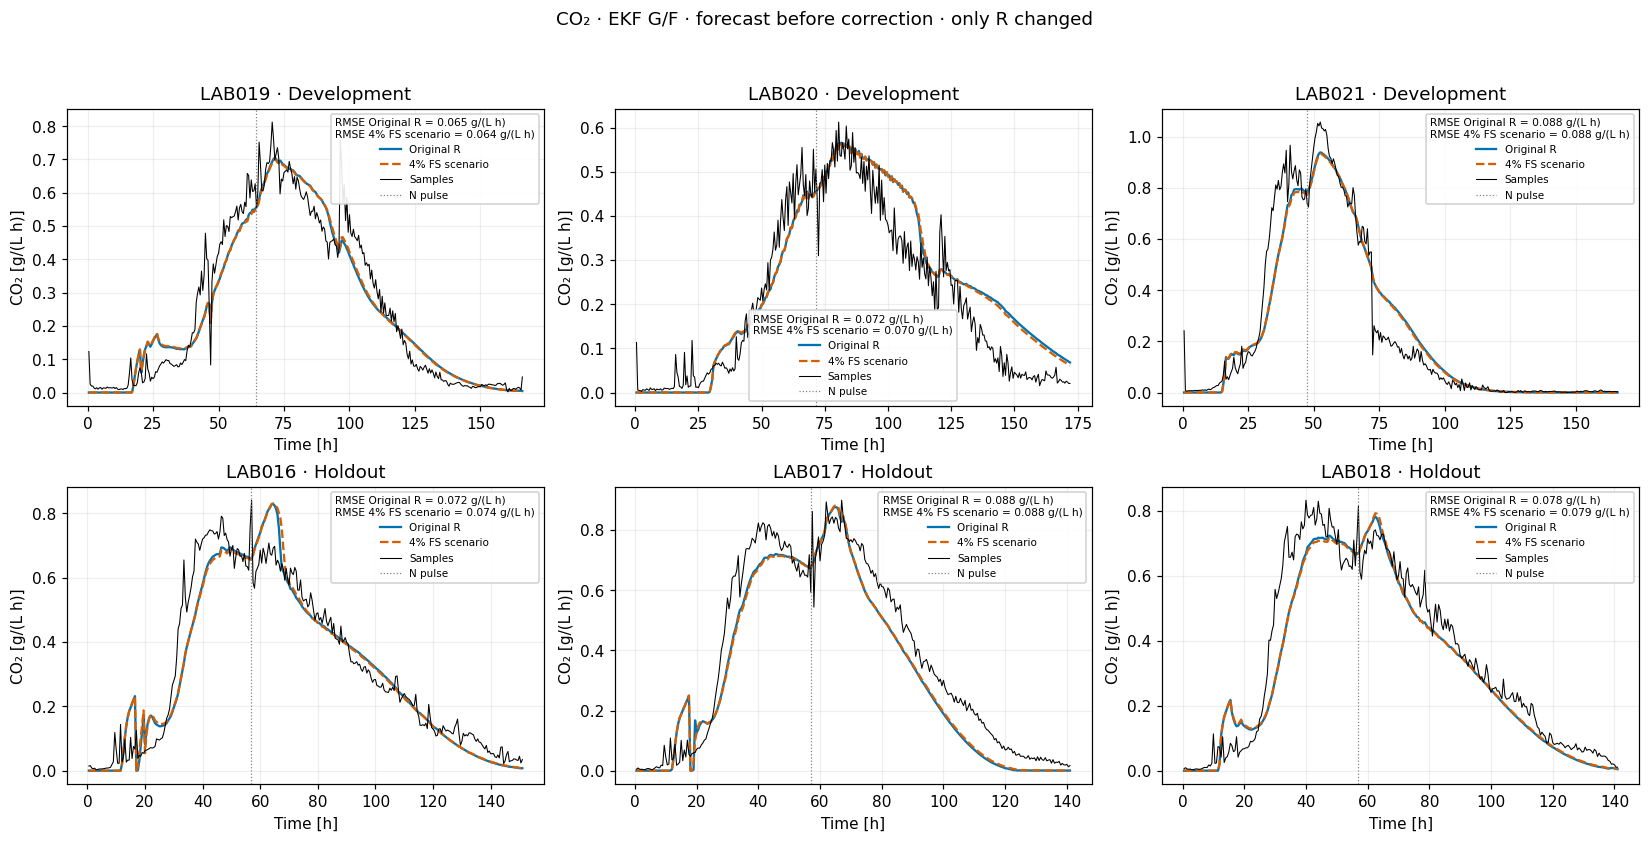

In [5]:
compare('CO2','CO₂')

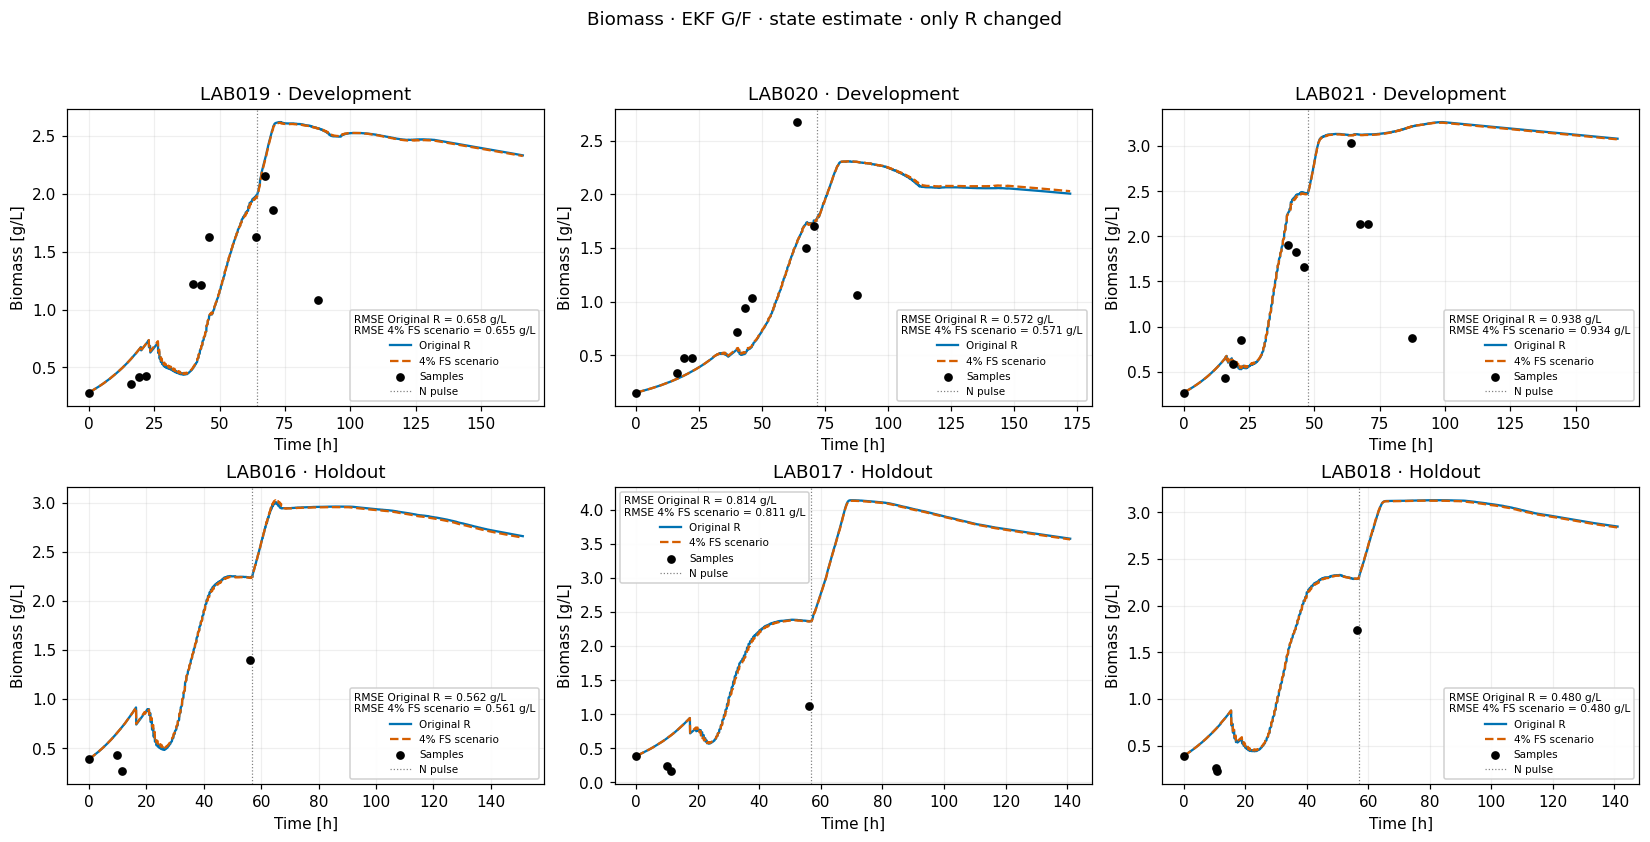

In [6]:
compare('X','Biomass')

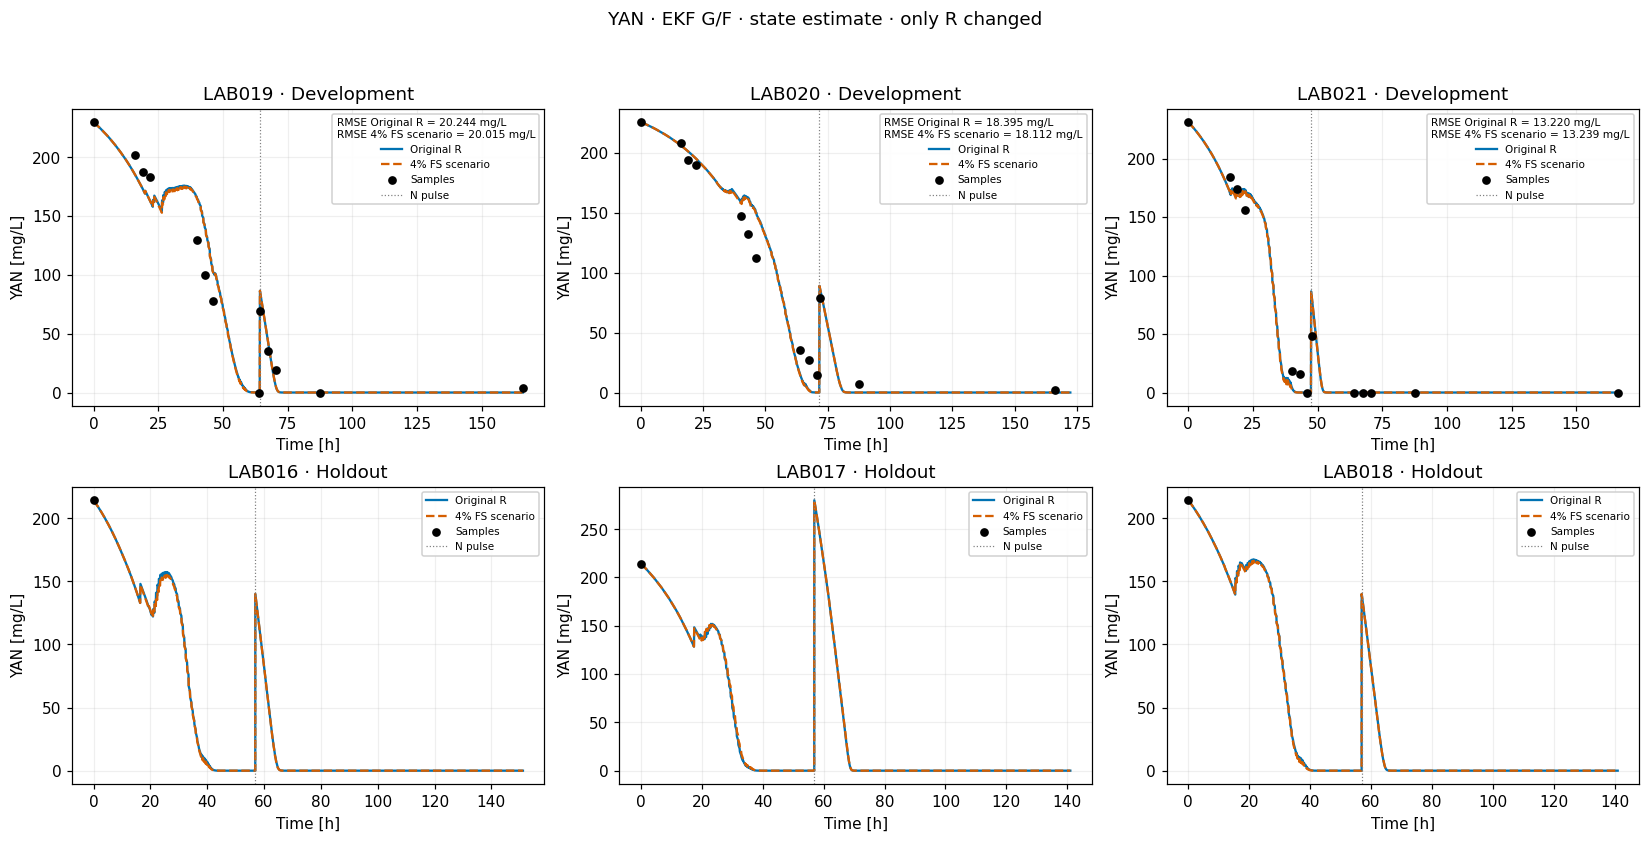

In [7]:
compare('N','YAN')

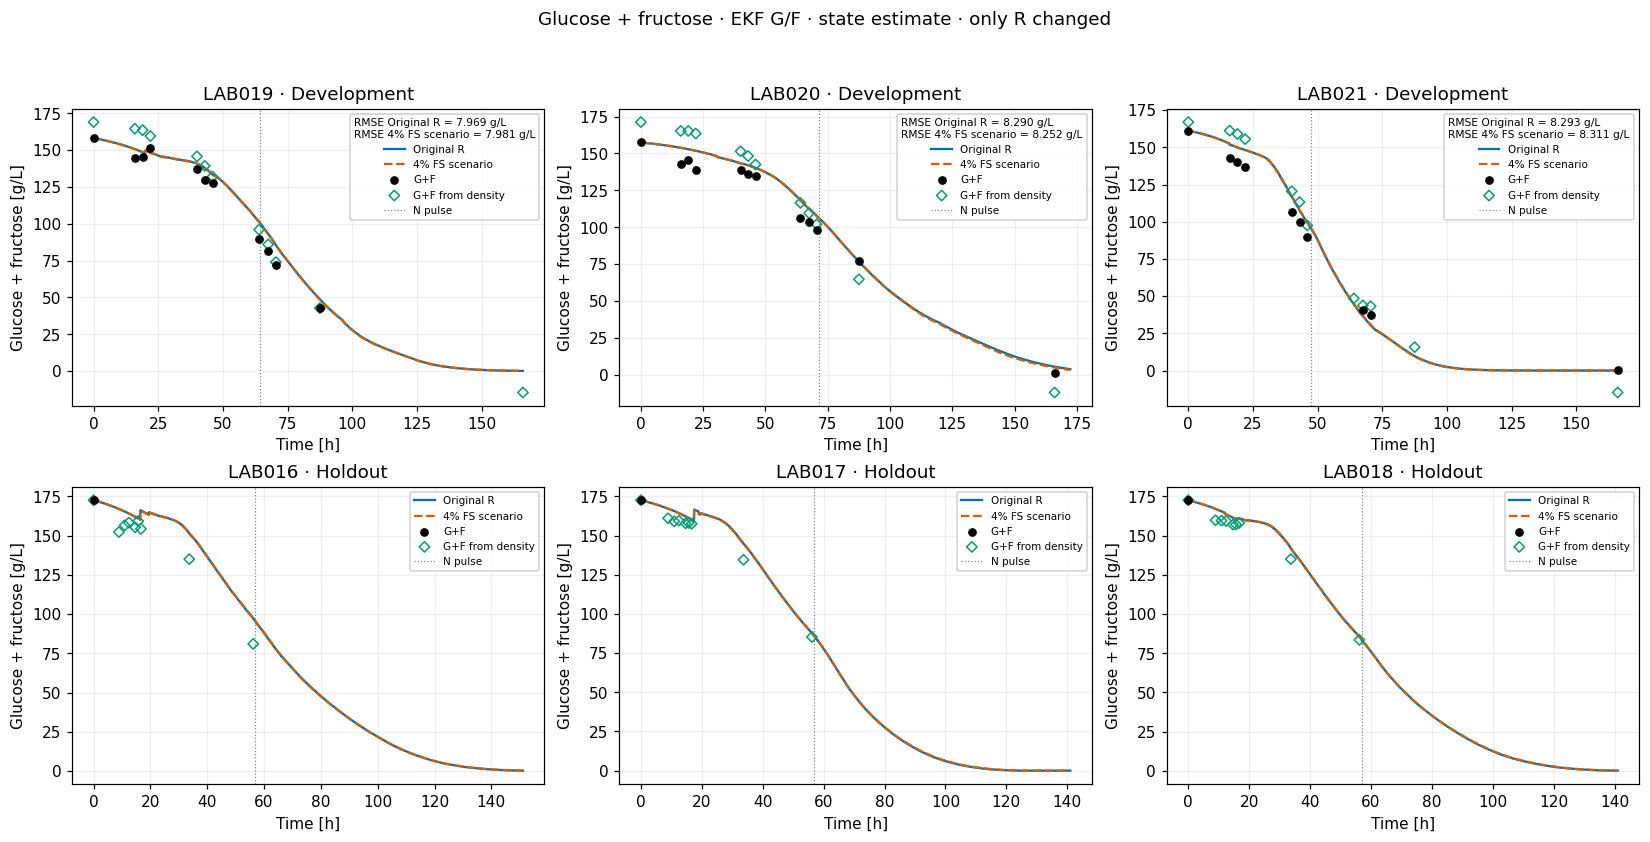

In [8]:
compare('GF','Glucose + fructose')

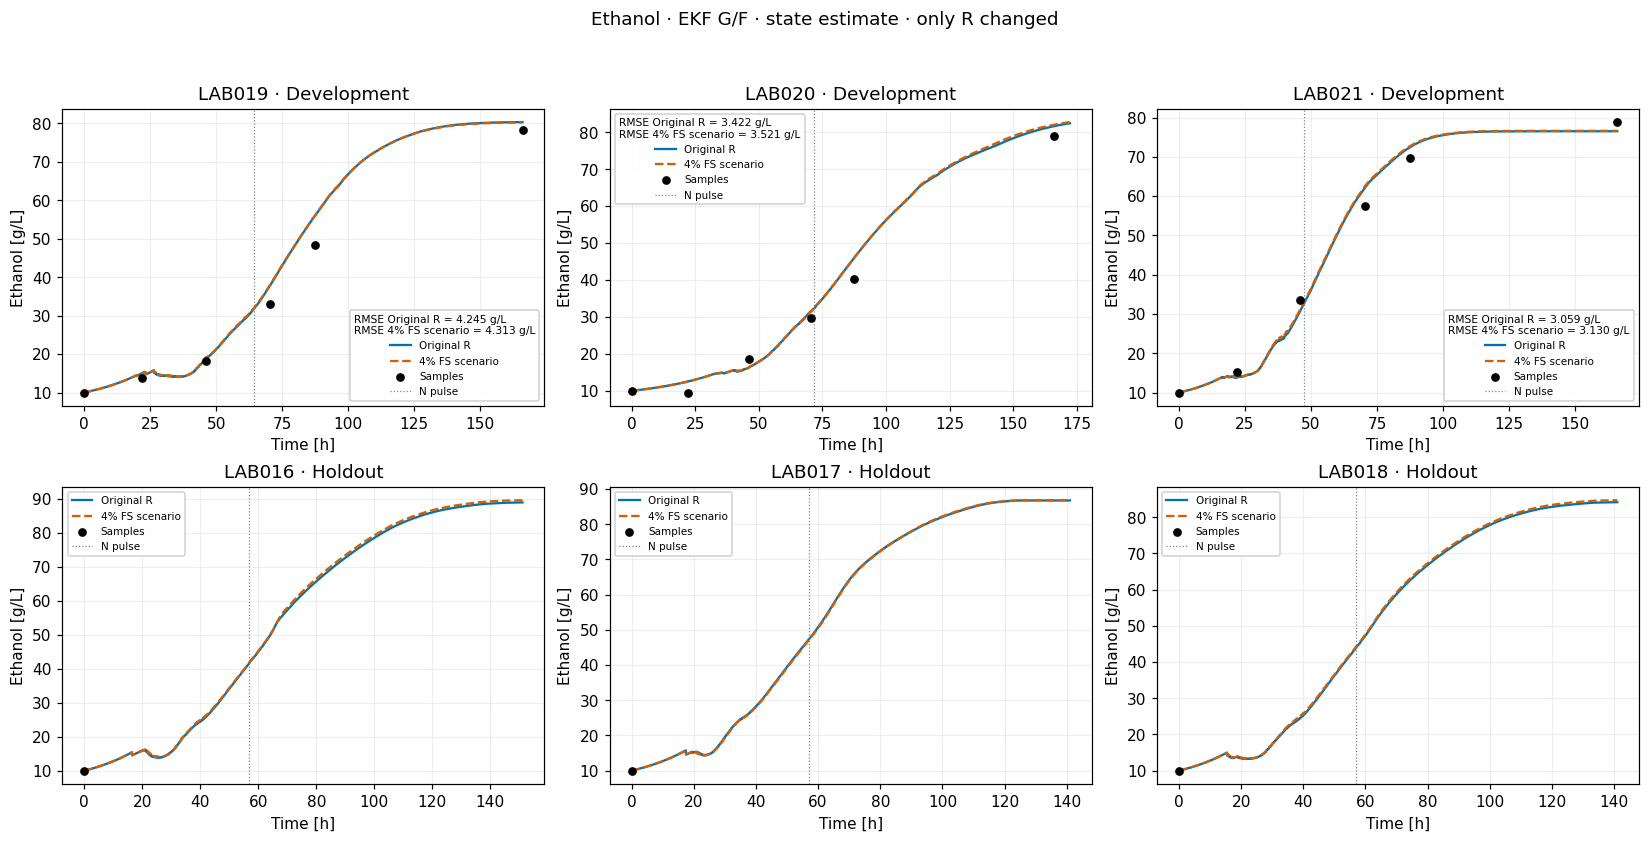

In [9]:
compare('E','Ethanol')

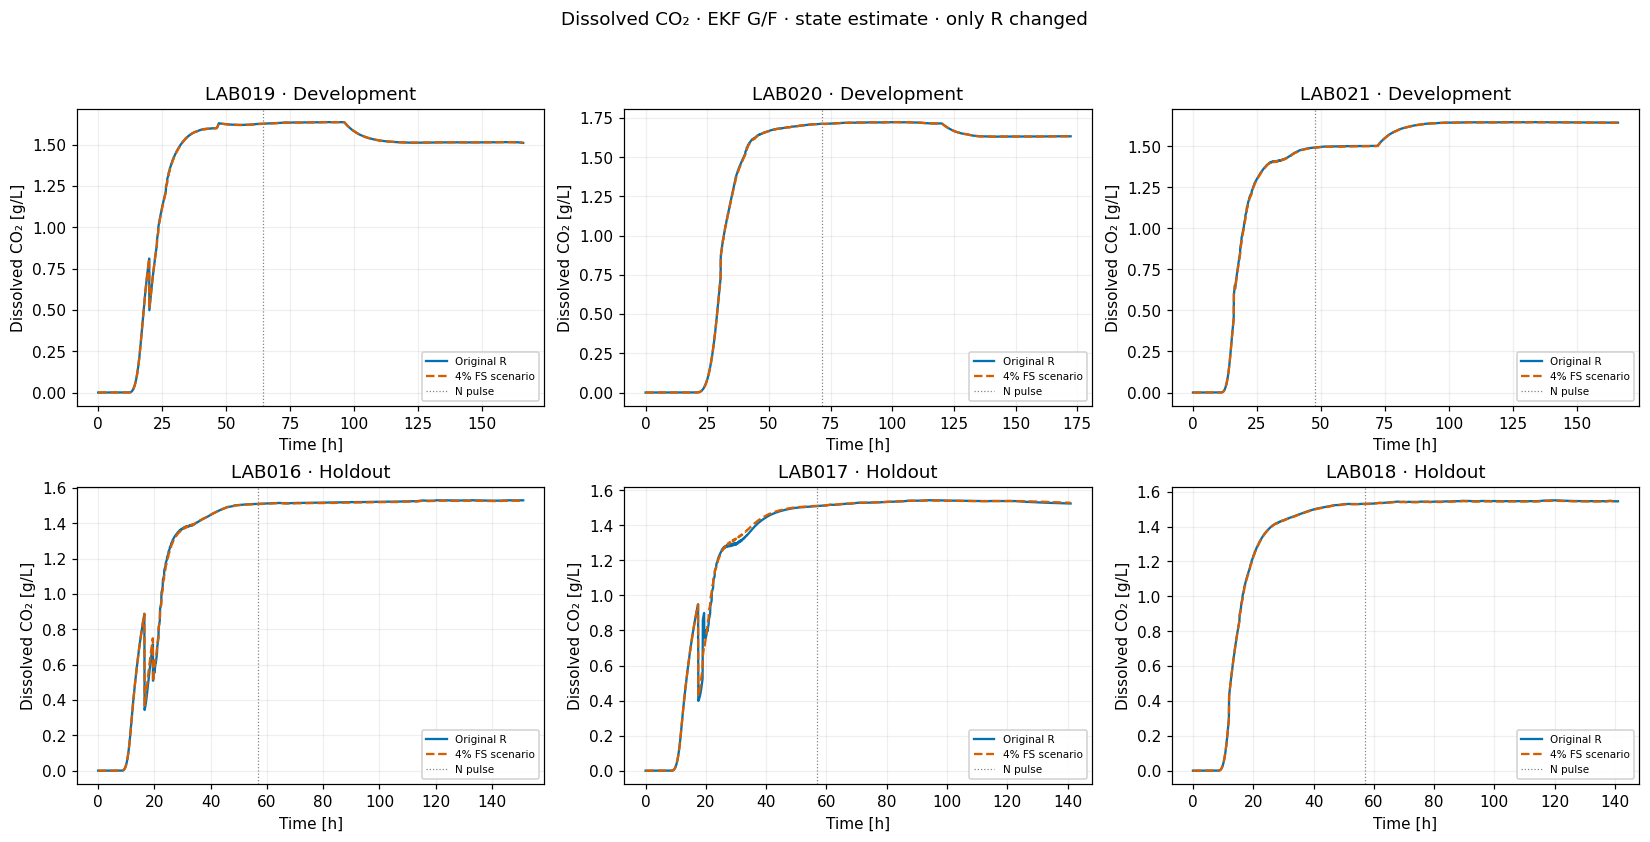

In [10]:
compare('Cd','Dissolved CO₂')

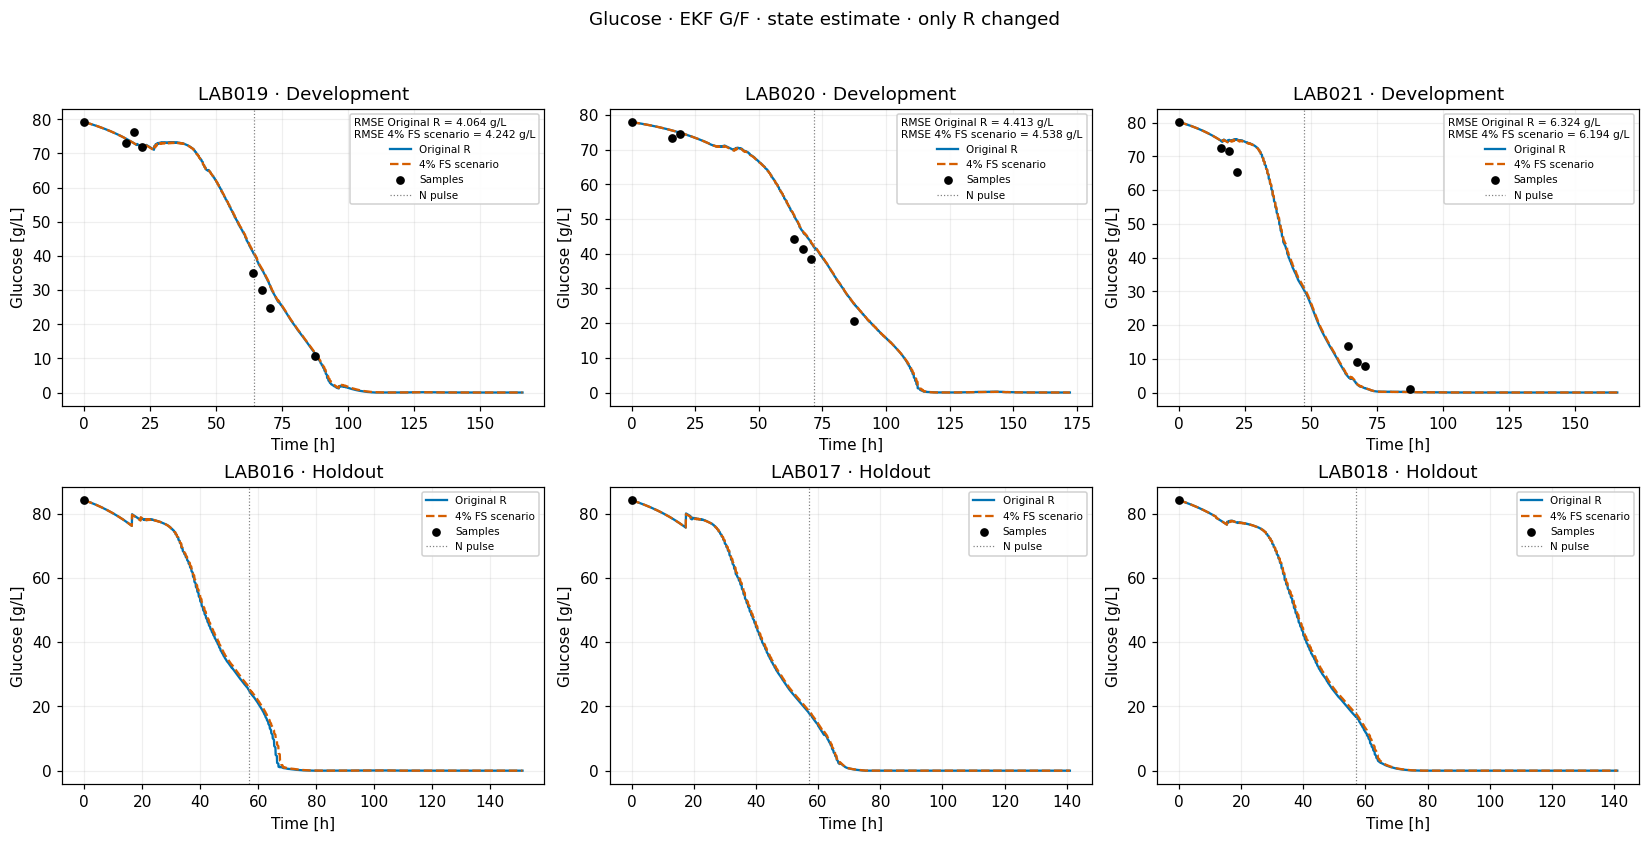

In [11]:
compare('G','Glucose')

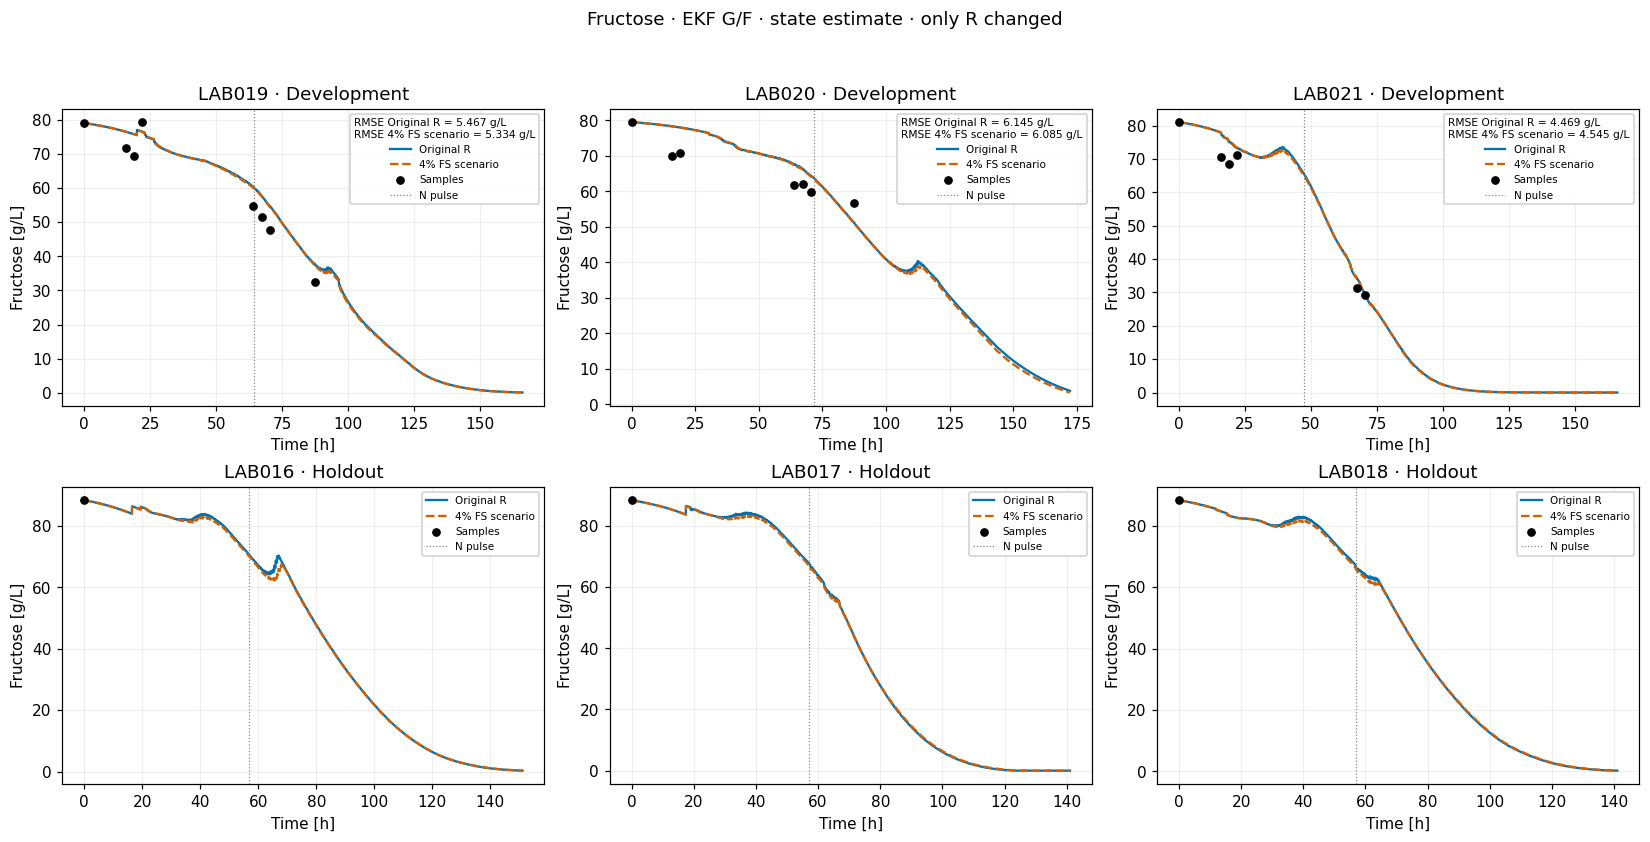

In [12]:
compare('F','Fructose')

## Comparación numérica y diagnósticos

El resumen separa desarrollo y holdout y promedia los RMSE por laboratorio dentro de cada grupo, no mezcla ambos conjuntos. Un menor RMSE químico no demuestra por sí solo una mejor incertidumbre. NIS y autocorrelación son diagnósticos aproximados bajo selección de ventanas y recortes; no una prueba metrológica de que R sea correcto.

case                                     4% FS scenario  Original R  Change [%]
role        LAB    variable unit    n                                          
Development LAB019 CO2      g/(L h) 332          0.0639      0.0646     -1.0509
                   E        g/L     5            4.3133      4.2452      1.6046
                   F        g/L     7            5.3338      5.4674     -2.4436
                   G        g/L     7            4.2422      4.0639      4.3860
                   GF       g/L     10           7.9808      7.9689      0.1496
                   N        mg/L    12          20.0147     20.2440     -1.1328
                   X        g/L     10           0.6549      0.6581     -0.4812
            LAB020 CO2      g/(L h) 344          0.0703      0.0720     -2.3473
                   E        g/L     5            3.5207      3.4216      2.8952
                   F        g/L     6            6.0846      6.1454     -0.9899
                   G        g/L     6            4.5379      4.4126      2.8390
                   GF       g/L     11           8.2518      8.2895     -0.4554
                   N        mg/L    12          18.1116     18.3953     -1.5422
                   X        g/L     10           0.5705      0.5723     -0.3190
            LAB021 CO2      g/(L h) 332          0.0877      0.0877      0.0621
                   E        g/L     5            3.1300      3.0593      2.3110
                   F        g/L     5            4.5447      4.4690      1.6944
                   G        g/L     7            6.1939      6.3238     -2.0544
                   GF       g/L     9            8.3109      8.2934      0.2100
                   N        mg/L    12          13.2389     13.2203      0.1406
                   X        g/L     10           0.9342      0.9383     -0.4434
Holdout     LAB016 CO2      g/(L h) 302          0.0739      0.0720      2.6544
                   X        g/L     3            0.5606      0.5618     -0.2022
            LAB017 CO2      g/(L h) 282          0.0875      0.0876     -0.0592
                   X        g/L     3            0.8112      0.8141     -0.3523
            LAB018 CO2      g/(L h) 282          0.0787      0.0779      0.9926
                   X        g/L     3            0.4802      0.4795      0.1406

case                          4% FS scenario  Original R  Change [%]
role        variable unit                                           
Development CO2      g/(L h)          0.0740      0.0748     -1.0322
            E        g/L              3.6546      3.5754      2.2178
            F        g/L              5.3210      5.3606     -0.7382
            G        g/L              4.9913      4.9335      1.1730
            GF       g/L              8.1811      8.1840     -0.0343
            N        mg/L            17.1217     17.2865     -0.9534
            X        g/L              0.7199      0.7229     -0.4221
Holdout     CO2      g/(L h)          0.0800      0.0791      1.1084
            X        g/L              0.6174      0.6185     -0.1795

,LAB,updates,standardized_bias,mean_NIS,innovation_coverage95,lag1,clips,min_eigenvalue,case,role
0,LAB019,217,0.2598,1.3805,0.9309,0.8092,62,0.0,Original R,Development
1,LAB020,223,-0.4355,1.3073,0.9327,0.7362,16,0.0,Original R,Development
2,LAB021,166,0.0171,3.5176,0.7108,0.9173,23,0.0,Original R,Development
3,LAB016,249,0.2318,1.3118,0.8996,0.8573,155,0.0,Original R,Holdout
4,LAB017,213,1.0706,2.1663,0.8779,0.7927,222,0.0,Original R,Holdout
5,LAB018,237,0.6150,1.5564,0.9030,0.8800,235,0.0,Original R,Holdout
6,LAB019,217,0.2323,1.1694,0.9493,0.8049,57,0.0,4% FS scenario,Development
7,LAB020,223,-0.4031,1.1299,0.9552,0.7349,16,0.0,4% FS scenario,Development
8,LAB021,166,0.0556,3.0736,0.7530,0.9172,24,0.0,4% FS scenario,Development
9,LAB016,249,0.2081,1.2043,0.9036,0.8673,156,0.0,4% FS scenario,Holdout


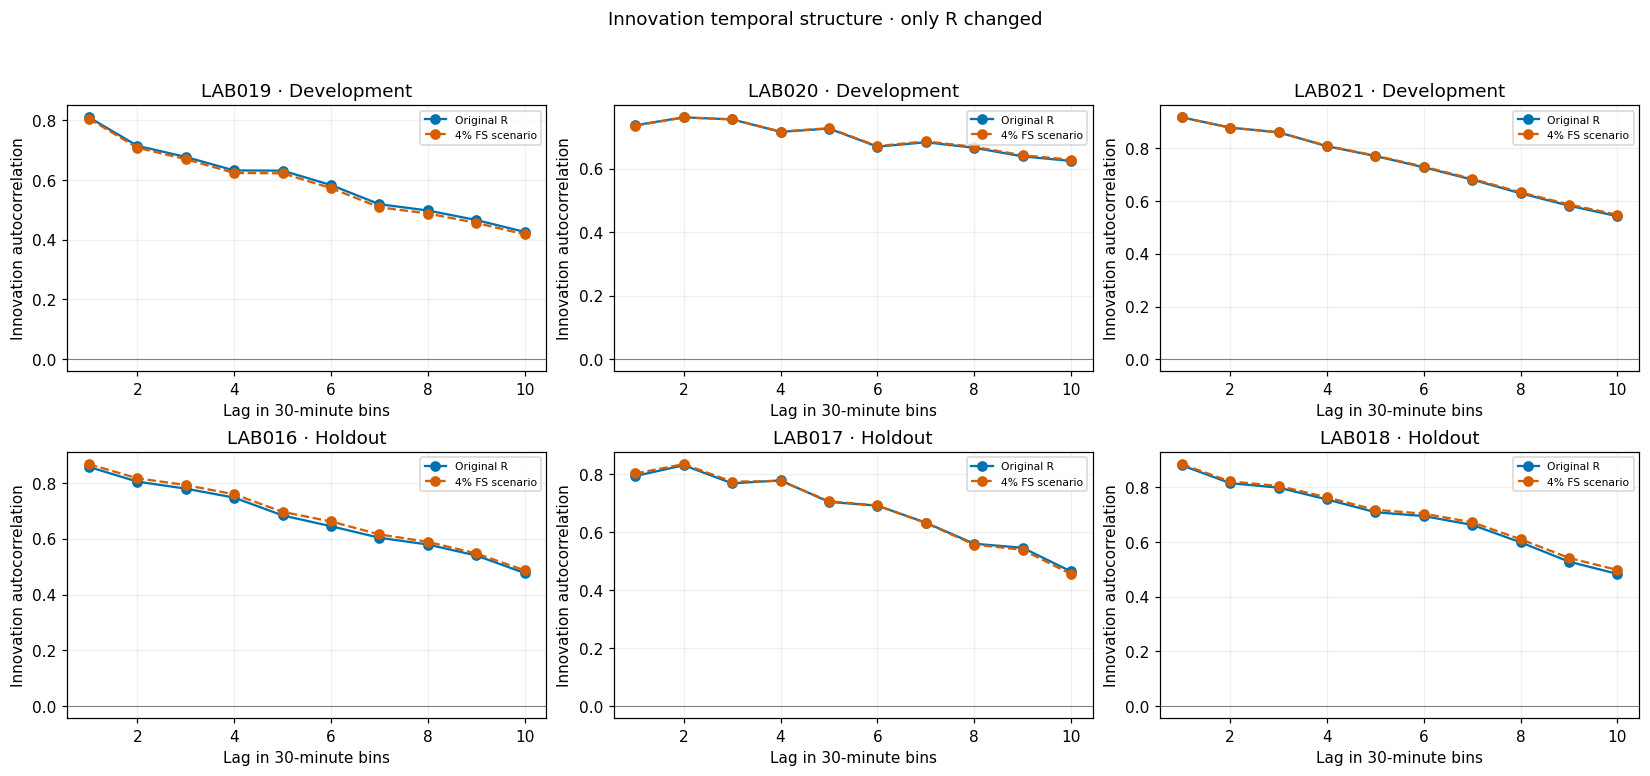

In [13]:
PER_LAB=METRICS.pivot(index=['role','LAB','variable','unit','n'],columns='case',values='RMSE')
PER_LAB['Change [%]']=100*(PER_LAB['4% FS scenario']/PER_LAB['Original R']-1)
display(PER_LAB.round(4))
SUMMARY=METRICS.groupby(['role','variable','unit','case']).RMSE.mean().unstack('case')
SUMMARY['Change [%]']=100*(SUMMARY['4% FS scenario']/SUMMARY['Original R']-1)
display(SUMMARY.round(4))
display(CHECKS.drop(columns='acf').round(4))
fig,axs=plt.subplots(2,3,figsize=(15,7))
for ax,lab in zip(axs.flat,LABS):
    for row in CHECKS.loc[CHECKS.LAB.eq(lab)].itertuples():
        ax.plot(range(1,11),row.acf,color=COLORS[row.case],ls=STYLES[row.case],marker='o',label=row.case)
    ax.axhline(0,c='gray',lw=.7);ax.set(title=lab+' · '+ROLE[lab],xlabel='Lag in 30-minute bins',ylabel='Innovation autocorrelation');ax.grid(alpha=.2);ax.legend(loc='best',fontsize=7)
fig.suptitle('Innovation temporal structure · only R changed',y=.995)
fig.tight_layout(pad=.7,rect=(0,0,1,.95));FIGURE_COUNT+=1;plt.show()


## Alcance del valor constante y conclusión

El factor de conversión utiliza el volumen real. En cambio, el R del escenario ejecutado se calculó a **2 L de referencia**. Si se propagara la misma especificación al volumen V, su valor sería $R(V)=R(2L)(2/V)^2$. La tabla siguiente muestra esa sensibilidad, pero no corresponde a un tercer filtro ejecutado.

La comparación puede mostrar cómo responde el estimador a una R mayor. No permite demostrar que ±4 % sea FS, que el error sea blanco o que una R constante represente todas las fases. No se toma una decisión sobre las fuentes de Q con este experimento.

In [14]:
display(pd.DataFrame([dict(reference_volume_L=v,sigma=CASES['4% FS scenario']*2/v,R=(CASES['4% FS scenario']*2/v)**2) for v in [2.,1.8,1.75]]))
display(Markdown('**Comparación descriptiva con parámetros congelados.** Las tablas separan desarrollo y holdout. No se ajustan ni se seleccionan parámetros o fuentes de ruido con LAB016–018. No se escriben tablas ni archivos de resultados fuera del notebook.'))
assert all(hashlib.sha256((ROOT/path).read_bytes()).hexdigest()==digest for path,digest in PROTECTED.items())
assert FIGURE_COUNT==9
assert set(METRICS.loc[METRICS.role.eq('Holdout'),'variable'])=={'CO2','X'}
verification=dict(allowed_labs=list(LABS),only_R_parameter_changed=True,Q_amplitudes=core.BASE_SIGMA.tolist(),
    gas_parameters=core.ARCHIVED_GAS.tolist(),R_values={k:v*v for k,v in CASES.items()},
    comparison_volume_reference_L=REFERENCE_VOLUME_L,figures=FIGURE_COUNT,existing_files_unchanged=len(PROTECTED))
display(pd.Series(verification,name="Verification"))
print('Existing notebooks, helpers, configurations and previous analysis results unchanged:',len(PROTECTED))
print('No fit or source selection; LAB019–021 and holdout LAB016–018 evaluated with frozen parameters.')


Existing notebooks, helpers, configurations and previous analysis results unchanged: 193
No fit or source selection; LAB019–021 and holdout LAB016–018 evaluated with frozen parameters.


,reference_volume_L,sigma,R
0,2.00,0.046695,0.002180
1,1.80,0.051884,0.002692
2,1.75,0.053366,0.002848


**Comparación descriptiva con parámetros congelados.** Las tablas separan desarrollo y holdout. No se ajustan ni se seleccionan parámetros o fuentes de ruido con LAB016–018. No se escriben tablas ni archivos de resultados fuera del notebook.

allowed_labs                      [LAB019, LAB020, LAB021, LAB016, LAB017, LAB018]
only_R_parameter_changed                                                      True
Q_amplitudes                                   [0.003, 0.08, 0.08, 0.01, 0.0, 0.0]
gas_parameters                           [0.15007991020720535, 0.6460643588058115]
R_values                         {'Original R': 0.0016, '4% FS scenario': 0.002...
comparison_volume_reference_L                                                  2.0
figures                                                                          9
existing_files_unchanged                                                       193
Name: Verification, dtype: object